In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

In [2]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split

In [4]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

In [5]:
import matplotlib.pyplot as plt

---

In [6]:
# Step 2: Create Dataset

data = {
    'HouseSize': [800, 1200, 1500, 2000, 900, 1800, 2500, 1100,
                  1600, 2200, 1300, 2800, 950, 1900, 2400, 1400,
                  1700, 2100, 1000, 2600],

    'FamilyMembers': [2, 3, 4, 5, 2, 4, 6, 3, 4, 5,
                      3, 6, 2, 5, 6, 3, 4, 5, 2, 6],

    'OutsideTemperature': [25, 30, 32, 35, 24, 33, 38, 28,
                            31, 36, 29, 40, 26, 34, 37, 30,
                            32, 35, 27, 39],

    'NumberOfAppliances': [5, 8, 10, 14, 6, 12, 18, 7,
                           11, 16, 9, 20, 5, 13, 17, 10,
                           12, 15, 6, 19],

    'SolarPanelCapacity': [0, 2, 3, 1, 0, 4, 5, 1,
                           2, 3, 0, 6, 1, 2, 4, 2,
                           3, 1, 0, 5],

    'DailyUsageHours': [4, 6, 7, 9, 4, 8, 11, 5,
                        7, 10, 6, 12, 4, 8, 10, 6,
                        7, 9, 5, 11],

    'EnergyConsumption': [8, 12, 16, 25, 9, 20, 35, 11,
                          17, 29, 13, 40, 8, 23, 32, 15,
                          18, 27, 10, 38]
}

df = pd.DataFrame(data)
df

,HouseSize,FamilyMembers,OutsideTemperature,NumberOfAppliances,SolarPanelCapacity,DailyUsageHours,EnergyConsumption
0,800,2,25,5,0,4,8
1,1200,3,30,8,2,6,12
2,1500,4,32,10,3,7,16
3,2000,5,35,14,1,9,25
4,900,2,24,6,0,4,9
5,1800,4,33,12,4,8,20
6,2500,6,38,18,5,11,35
7,1100,3,28,7,1,5,11
8,1600,4,31,11,2,7,17
9,2200,5,36,16,3,10,29


---

In [7]:
# Step 3: Handle Missing Values

imputer = SimpleImputer(strategy='mean')

df[df.columns] = imputer.fit_transform(df)

print("Missing Values After Imputation:")
print(df.isnull().sum())

Missing Values After Imputation:
HouseSize             0
FamilyMembers         0
OutsideTemperature    0
NumberOfAppliances    0
SolarPanelCapacity    0
DailyUsageHours       0
EnergyConsumption     0
dtype: int64


---

In [8]:
# Step 4: Separate Features and Target

X = df.drop('EnergyConsumption', axis=1)

y = df['EnergyConsumption']

---

In [9]:
# Step 5: Normalize the Dataset

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

---

In [10]:
# Step 6: Apply K-Means Clustering

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['EnergyCluster'] = kmeans.fit_predict(X_scaled)

print(df[['HouseSize', 'EnergyConsumption', 'EnergyCluster']])

    HouseSize  EnergyConsumption  EnergyCluster
0       800.0                8.0              1
1      1200.0               12.0              1
2      1500.0               16.0              0
3      2000.0               25.0              0
4       900.0                9.0              1
5      1800.0               20.0              0
6      2500.0               35.0              2
7      1100.0               11.0              1
8      1600.0               17.0              0
9      2200.0               29.0              0
10     1300.0               13.0              1
11     2800.0               40.0              2
12      950.0                8.0              1
13     1900.0               23.0              0
14     2400.0               32.0              2
15     1400.0               15.0              1
16     1700.0               18.0              0
17     2100.0               27.0              0
18     1000.0               10.0              1
19     2600.0               38.0        

---

In [11]:
# Step 7: Add Cluster Labels to Features

X['EnergyCluster'] = df['EnergyCluster']

print(X.head())

   HouseSize  FamilyMembers  OutsideTemperature  NumberOfAppliances  \
0      800.0            2.0                25.0                 5.0   
1     1200.0            3.0                30.0                 8.0   
2     1500.0            4.0                32.0                10.0   
3     2000.0            5.0                35.0                14.0   
4      900.0            2.0                24.0                 6.0   

   SolarPanelCapacity  DailyUsageHours  EnergyCluster  
0                 0.0              4.0              1  
1                 2.0              6.0              1  
2                 3.0              7.0              0  
3                 1.0              9.0              0  
4                 0.0              4.0              1  


---

In [12]:
# Step 8: Split the Dataset

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

---

In [13]:
# Step 9: Train Gradient Boosting Regressor

model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


---

In [14]:
# Step 10: Predict and Evaluate the Model

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 0.8623544951408264
Mean Squared Error: 1.2748541829184408
Root Mean Squared Error: 1.1290944083283916
R2 Score: 0.9746297675041107


---

In [15]:
# Step 11: Display Feature Importance

importance = pd.DataFrame({'Feature': X.columns, 'Importance': model.feature_importances_})

importance = importance.sort_values(by='Importance', ascending=False)

In [16]:
importance

,Feature,Importance
0,HouseSize,0.313682
5,DailyUsageHours,0.200128
3,NumberOfAppliances,0.196754
2,OutsideTemperature,0.178804
4,SolarPanelCapacity,0.046719
1,FamilyMembers,0.036694
6,EnergyCluster,0.027219


---

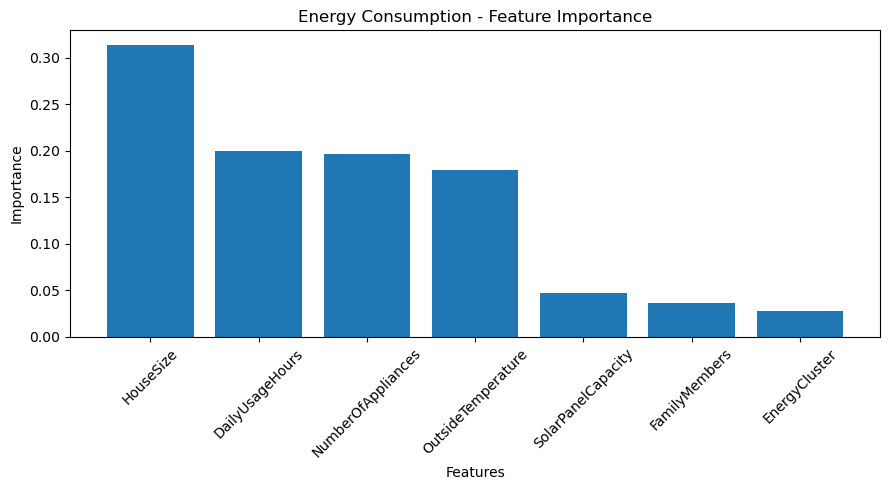

In [17]:
# Visualize feature importance:

plt.figure(figsize=(9, 5))

plt.bar(importance['Feature'], importance['Importance'])

plt.title("Energy Consumption - Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

---

In [18]:
# Step 12: Predict Energy Consumption for a New Household

new_household = pd.DataFrame({'HouseSize': [1800], 'FamilyMembers': [4], 'OutsideTemperature': [35], 'NumberOfAppliances': [12], 'SolarPanelCapacity': [3], 'DailyUsageHours': [8]})

In [19]:
# Apply the same scaler

new_household_scaled = scaler.transform(new_household)

In [20]:
# Predict household cluster

new_cluster = kmeans.predict(new_household_scaled)

In [21]:
# Add cluster information

new_household['EnergyCluster'] = new_cluster

In [22]:
# Predict energy consumption

predicted_energy = model.predict(new_household)

In [23]:
print("Predicted Energy Consumption:", round(predicted_energy[0], 2), "kWh")

Predicted Energy Consumption: 21.71 kWh
